# Notebook 03: Duality and Metric Flow Between the Parameter Manifold ($\Theta$) and Data Manifolds ($\mathcal{M}_\ell$)

## Research Objective
We investigate the information-geometric interplay between:
1. **The Parameter Manifold ($\Theta \subset \mathbb{R}^{422}$)** equipped with the $422 \times 422$ **Parameter Fisher Information Matrix (FIM)**:
   $$F_{\mu\nu}(\theta) = \mathbb{E}_{x \sim \mathcal{D}} \left[ \sum_{c=0}^1 p_\theta(y=c|x) \frac{\partial \log p_\theta(y=c|x)}{\partial \theta^\mu} \frac{\partial \log p_\theta(y=c|x)}{\partial \theta^\nu} \right]$$
2. **The Data Manifold ($\mathcal{M}_0 \subset \mathbb{R}^2$)** equipped with the $2 \times 2$ **Data Information Matrix (DIM)** (**Tron, Fioresi, Novelli, & Latini, 2024/2026**; **Fasina et al., 2023**):
   $$\mathrm{DIM}_{ij}(x; \theta) = \sum_{c=0}^1 p_\theta(y=c|x) \frac{\partial \log p_\theta(y=c|x)}{\partial x^i} \frac{\partial \log p_\theta(y=c|x)}{\partial x^j}$$

We further test **Halverson & Ruehle (2023)**'s *Metric Flow* framework by measuring how perturbations along the top vs. bottom eigenvectors of $F_{\mu\nu}(\theta)$ deform the layerwise metric tensor $g^{(\ell)}_{ij}(x; \theta)$ and Gaussian curvature $K^{(\ell)}(x; \theta)$, and compare **Euclidean Gradient Descent** against **Natural Gradient Descent** on $\Theta$.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.geometry import (
    MoonsMLP,
    get_moons_dataset,
    make_evaluation_grid,
    compute_parameter_fim,
    compute_data_information_matrix,
    compute_layer_geometry,
)

X_train, y_train, X_test, y_test = get_moons_dataset(n_train=240, n_test=120, noise=0.10, seed=42)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=25, padding=0.45)

model = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)
optimizer = torch.optim.Adam(model.parameters(), lr=0.015)
criterion = nn.CrossEntropyLoss()

snapshots = {0: copy.deepcopy(model.state_dict())}
for ep in range(1, 181):
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()
    optimizer.step()
    if ep in [15, 60, 180]:
        snapshots[ep] = copy.deepcopy(model.state_dict())

print("Captured parameter manifold checkpoints at epochs:", list(snapshots.keys()))

Captured parameter manifold checkpoints at epochs: [0, 15, 60, 180]


## 1. Co-Evolution of the $422 \times 422$ Parameter FIM Spectrum and $2 \times 2$ Data Information Matrix
We compute the eigenspectrum of $F_{\mu\nu}(\theta)$ and the spatial trace of $\mathrm{DIM}_{ij}(x; \theta)$ across training checkpoints. Notice how the parameter manifold concentrates its Fisher information into a low-dimensional stiff subspace while $\mathrm{Tr}(\mathrm{DIM}(x; \theta))$ sharpens into a singular foliation along the decision boundary (**Tron et al., 2024**).

Epoch   0 | Tr(FIM) =    6.010 | E[Tr(DIM)] =    0.009 | FIM Effective Rank =   2.43 / 422
Epoch  15 | Tr(FIM) =   10.386 | E[Tr(DIM)] =    0.850 | FIM Effective Rank =   2.59 / 422
Epoch  60 | Tr(FIM) =   13.318 | E[Tr(DIM)] =    0.732 | FIM Effective Rank =   2.49 / 422
Epoch 180 | Tr(FIM) =    0.667 | E[Tr(DIM)] =    0.077 | FIM Effective Rank =   3.86 / 422


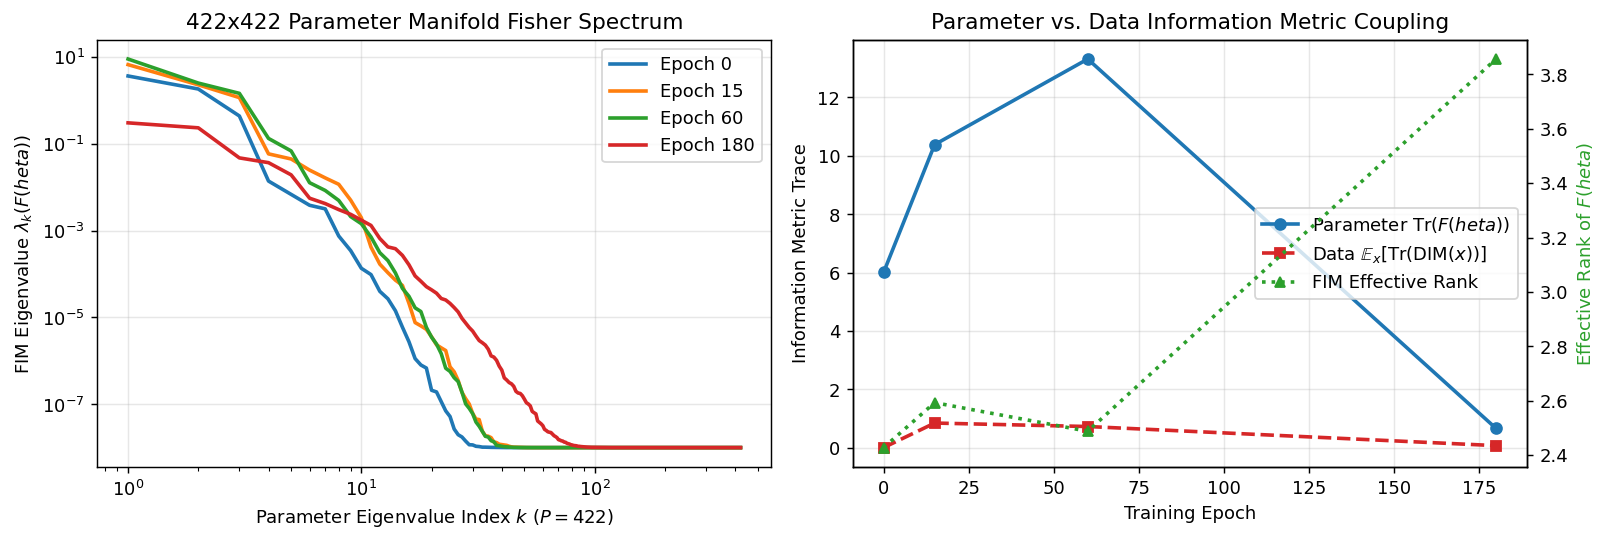

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
probe = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)

ep_list = [0, 15, 60, 180]
fim_traces, dim_traces, eff_ranks = [], [], []

for ep in ep_list:
    probe.load_state_dict(snapshots[ep])
    fim, _ = compute_parameter_fim(probe, X_train, damping=1e-8)
    evals = torch.linalg.eigvalsh(fim).flip(0).clamp(min=1e-10).detach().numpy()
    axes[0].plot(range(1, len(evals) + 1), evals, lw=2, label=f"Epoch {ep}")

    p_spec = evals / np.sum(evals)
    eff_rank = float(np.exp(-np.sum(p_spec * np.log(p_spec + 1e-15))))
    dim_mat = compute_data_information_matrix(probe, X_train)
    fim_traces.append(float(np.sum(evals)))
    dim_traces.append(float(torch.diagonal(dim_mat, dim1=-2, dim2=-1).sum(-1).mean().item()))
    eff_ranks.append(eff_rank)

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Parameter Eigenvalue Index $k$ ($P = 422$)")
axes[0].set_ylabel("FIM Eigenvalue $\lambda_k(F(\theta))$")
axes[0].set_title("422x422 Parameter Manifold Fisher Spectrum")
axes[0].legend()
axes[0].grid(alpha=0.3)

ax2 = axes[1].twinx()
axes[1].plot(ep_list, fim_traces, "o-", color="#1f77b4", lw=2, label="Parameter $\mathrm{Tr}(F(\theta))$")
axes[1].plot(ep_list, dim_traces, "s--", color="#d62728", lw=2, label="Data $\mathbb{E}_x[\mathrm{Tr}(\mathrm{DIM}(x))]$")
ax2.plot(ep_list, eff_ranks, "^:", color="#2ca02c", lw=2, label="FIM Effective Rank")
axes[1].set_xlabel("Training Epoch")
axes[1].set_ylabel("Information Metric Trace")
ax2.set_ylabel("Effective Rank of $F(\theta)$", color="#2ca02c")
axes[1].set_title("Parameter vs. Data Information Metric Coupling")
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc="center right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for ep, ft, dt, er in zip(ep_list, fim_traces, dim_traces, eff_ranks):
    print(f"Epoch {ep:3d} | Tr(FIM) = {ft:8.3f} | E[Tr(DIM)] = {dt:8.3f} | FIM Effective Rank = {er:6.2f} / 422")

## 2. Singular Foliation of the Input Data Manifold via the Data Information Matrix (DIM)
For a binary classifier, the unregularized $2 \times 2$ Data Information Matrix $\mathrm{DIM}_{ij}(x) = p(1-p) \nabla_i f_{\text{logit}} \nabla_j f_{\text{logit}}$ has rank at most $1$. Its kernel eigenvector $v_{\ker}(x)$ spans the tangent distribution to the **1D foliation leaves** of constant class probability (**Benfenati & Marta, 2023**; **Tron et al., 2024**), while its principal eigenvector $v_{\max}(x)$ points along the maximum information gradient across the decision boundary.

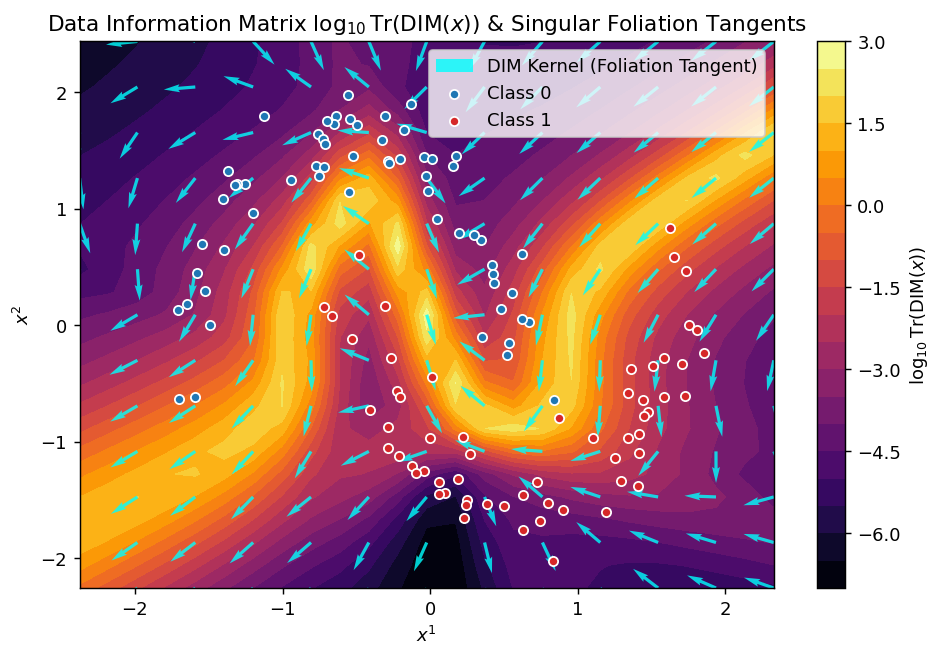

In [3]:
dim_grid = compute_data_information_matrix(model, grid_pts, eps=1e-9)
tr_dim = torch.diagonal(dim_grid, dim1=-2, dim2=-1).sum(-1).detach().numpy().reshape(xx.shape)
evals_d, evecs_d = torch.linalg.eigh(dim_grid)
# Kernel eigenvector (index 0, smallest eigenvalue) is tangent to foliation leaves
v_leaf = evecs_d[:, :, 0].detach().numpy()
u_leaf = v_leaf[:, 0].reshape(xx.shape)
w_leaf = v_leaf[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
cf = ax.contourf(xx, yy, np.log10(tr_dim + 1e-7), levels=22, cmap="inferno")
ax.quiver(xx[::2, ::2], yy[::2, ::2], u_leaf[::2, ::2], w_leaf[::2, ::2], color="cyan", alpha=0.8, scale=22, headwidth=2.5, label="DIM Kernel (Foliation Tangent)")
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", edgecolors="w", s=26, label="Class 0")
ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", edgecolors="w", s=26, label="Class 1")
ax.set_title("Data Information Matrix $\log_{10}\mathrm{Tr}(\mathrm{DIM}(x))$ & Singular Foliation Tangents")
ax.set_xlabel("$x^1$")
ax.set_ylabel("$x^2$")
ax.legend(loc="upper right")
plt.colorbar(cf, ax=ax, label="$\log_{10}\mathrm{Tr}(\mathrm{DIM}(x))$")
plt.tight_layout()
plt.show()

## 3. Metric Flow Sensitivity: Perturbing $\Theta$ Along Top vs. Null FIM Eigenvectors
To directly test how movements on the parameter manifold $\Theta$ induce metric and curvature flows on the data manifold $\mathcal{M}_5$ (**Halverson & Ruehle, 2023**), we perturb $\theta \mapsto \theta + \delta \cdot v^{(k)}$ along unit eigenvectors $v^{(k)}$ of $F(\theta)$ for $k \in \{1, 2, 5, 20, 100, 300\}$ and measure the induced change in the data pullback metric $\|\Delta g^{(5)}(x)\|_F$ and Gaussian curvature $\|\Delta K^{(5)}(x)\|_2$.

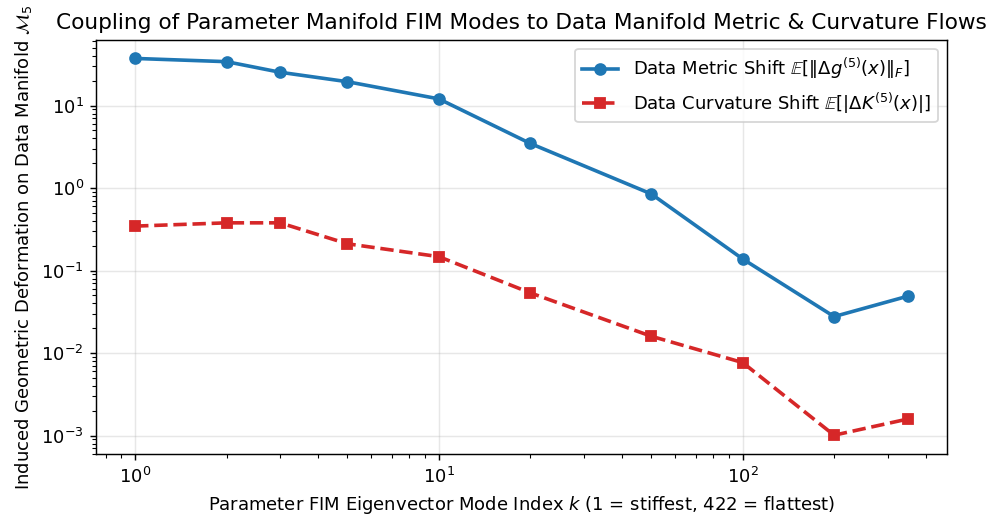

In [4]:
fim, _ = compute_parameter_fim(model, X_train, damping=1e-8)
fim_evals, fim_evecs = torch.linalg.eigh(fim)
fim_evals = fim_evals.flip(0)
fim_evecs = fim_evecs.flip(1)

base_params = {k: v.detach().clone() for k, v in model.named_parameters()}
base_geom = compute_layer_geometry(model, X_test, layer_idx=5, metric_mode="graph", params=base_params)

def unflatten_like(vec: torch.Tensor, template: dict) -> dict:
    out = {}
    offset = 0
    for k, t in template.items():
        numel = t.numel()
        out[k] = t + vec[offset : offset + numel].reshape(t.shape)
        offset += numel
    return out

modes_to_test = [0, 1, 2, 4, 9, 19, 49, 99, 199, 350]
delta_scale = 0.08
metric_shifts, curv_shifts, mode_evals = [], [], []

for m_idx in modes_to_test:
    v_vec = fim_evecs[:, m_idx] * delta_scale
    pert_params = unflatten_like(v_vec, base_params)
    pert_geom = compute_layer_geometry(model, X_test, layer_idx=5, metric_mode="graph", params=pert_params)
    dg = (pert_geom["g"] - base_geom["g"]).norm(dim=(-2, -1)).mean().item()
    dK = (pert_geom["K"] - base_geom["K"]).abs().mean().item()
    metric_shifts.append(dg)
    curv_shifts.append(dK)
    mode_evals.append(fim_evals[m_idx].item())

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot([m + 1 for m in modes_to_test], metric_shifts, "o-", lw=2, color="#1f77b4", label="Data Metric Shift $\mathbb{E}[\|\Delta g^{(5)}(x)\|_F]$")
ax.plot([m + 1 for m in modes_to_test], curv_shifts, "s--", lw=2, color="#d62728", label="Data Curvature Shift $\mathbb{E}[|\Delta K^{(5)}(x)|]$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Parameter FIM Eigenvector Mode Index $k$ (1 = stiffest, 422 = flattest)")
ax.set_ylabel("Induced Geometric Deformation on Data Manifold $\mathcal{M}_5$")
ax.set_title("Coupling of Parameter Manifold FIM Modes to Data Manifold Metric & Curvature Flows")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Euclidean Gradient Descent vs. Riemannian Natural Gradient Descent on $\Theta$
We compare standard Euclidean Gradient Descent ($\Delta \theta = -\eta \nabla_\theta \mathcal{L}$) with damped **Natural Gradient Descent** ($\Delta \theta = -\eta (F(\theta) + \lambda I)^{-1} \nabla_\theta \mathcal{L}$), tracking both classification loss and the smoothness of the induced Gaussian curvature $K^{(5)}(x)$ on the data manifold.

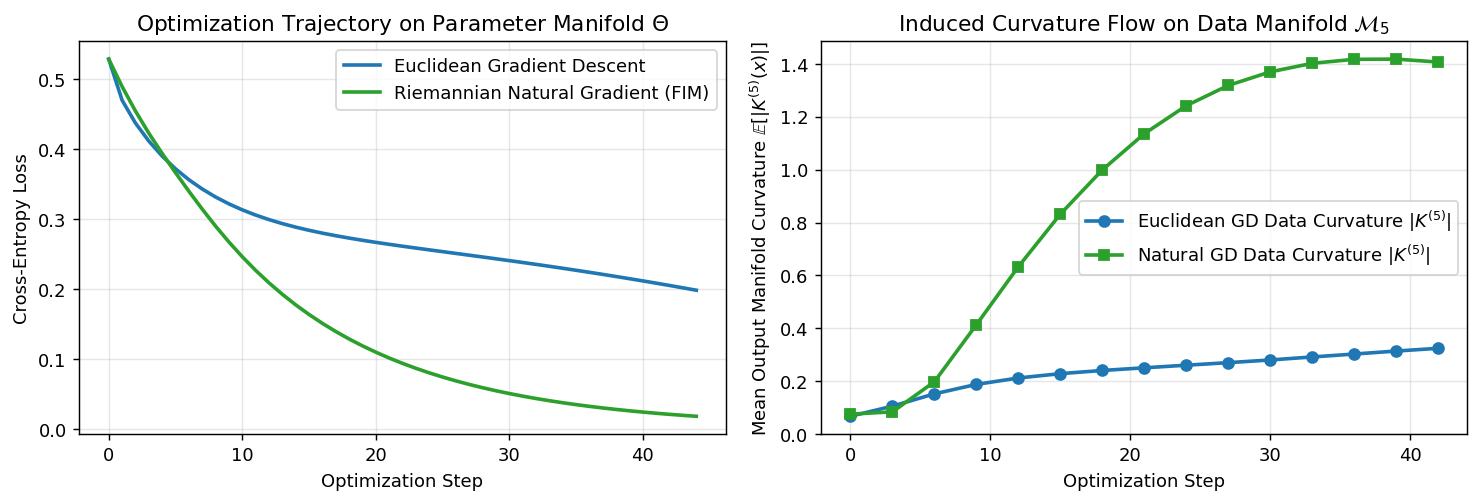

In [5]:
def run_optimizer_comparison(steps: int = 45):
    m_gd = MoonsMLP(activation="tanh", seed=11)
    m_ngd = copy.deepcopy(m_gd)
    crit = nn.CrossEntropyLoss()

    gd_losses, ngd_losses, gd_curv, ngd_curv = [], [], [], []
    for step in range(steps):
        # 1. Euclidean GD
        for p in m_gd.parameters():
            if p.grad is not None:
                p.grad.zero_()
        l_gd = crit(m_gd(X_train), y_train)
        l_gd.backward()
        with torch.no_grad():
            for p in m_gd.parameters():
                p -= 0.15 * p.grad
        gd_losses.append(l_gd.item())

        # 2. Natural Gradient Descent on Parameter Manifold
        for p in m_ngd.parameters():
            if p.grad is not None:
                p.grad.zero_()
        l_ngd = crit(m_ngd(X_train), y_train)
        l_ngd.backward()
        fim_curr, _ = compute_parameter_fim(m_ngd, X_train, damping=0.02)
        g_flat = torch.cat([p.grad.reshape(-1) for p in m_ngd.parameters()])
        nat_step = torch.linalg.solve(fim_curr, g_flat)
        with torch.no_grad():
            offset = 0
            for p in m_ngd.parameters():
                n = p.numel()
                p -= 0.08 * nat_step[offset : offset + n].reshape(p.shape)
                offset += n
        ngd_losses.append(l_ngd.item())

        if step % 3 == 0:
            K_gd = compute_layer_geometry(m_gd, X_test[:40], layer_idx=5, metric_mode="graph")["K"].abs().mean().item()
            K_ngd = compute_layer_geometry(m_ngd, X_test[:40], layer_idx=5, metric_mode="graph")["K"].abs().mean().item()
            gd_curv.append((step, K_gd))
            ngd_curv.append((step, K_ngd))

    return gd_losses, ngd_losses, gd_curv, ngd_curv

gd_l, ngd_l, gd_k, ngd_k = run_optimizer_comparison(45)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
axes[0].plot(gd_l, lw=2, color="#1f77b4", label="Euclidean Gradient Descent")
axes[0].plot(ngd_l, lw=2, color="#2ca02c", label="Riemannian Natural Gradient (FIM)")
axes[0].set_xlabel("Optimization Step")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Optimization Trajectory on Parameter Manifold $\Theta$")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot([x[0] for x in gd_k], [x[1] for x in gd_k], "o-", lw=2, color="#1f77b4", label="Euclidean GD Data Curvature $|K^{(5)}|$")
axes[1].plot([x[0] for x in ngd_k], [x[1] for x in ngd_k], "s-", lw=2, color="#2ca02c", label="Natural GD Data Curvature $|K^{(5)}|$")
axes[1].set_xlabel("Optimization Step")
axes[1].set_ylabel("Mean Output Manifold Curvature $\mathbb{E}[|K^{(5)}(x)|]$")
axes[1].set_title("Induced Curvature Flow on Data Manifold $\mathcal{M}_5$")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()